# 汽车样本市场增长分析

业务问题：样本中的哪些品牌和车系在增长？增长来自哪些产品？这种增长是否持续？

分析范围：销量与配置，不包含评论。主比较2025与2024完整自然年，近期观察2026上半年对2025上半年。
本Notebook已执行并保留输出。完整处理代码位于同目录 `analysis_main.py`。

数据来自 Yemyu/china-auto-market-analysis，原始平台为太平洋汽车。原文件不修改；完整性仅指下载快照，不代表原始采集无遗漏。

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'analysis_main.py').exists():
    raise FileNotFoundError('请从项目根目录打开本 Notebook')
sys.path.insert(0, str(ROOT))
import analysis_main as project
pd.set_option('display.max_columns', 20)
print('解释器：', sys.executable)
manifest = json.loads((ROOT / 'data/source_manifest.json').read_text(encoding='utf-8'))
print('固定提交：', manifest['commit'])
display(pd.DataFrame(manifest['files']))

解释器： [项目 Python 环境]
固定提交： 135dbf3483403b69b9626f39a9ca5ce091ce6c73


,file,repository_path,url,sha256
0,sales_filtered_24m.csv,data/processed/sales_filtered_24m.csv,https://raw.githubusercontent.com/Yemyu/china-...,31bf8dc43c80a452dc489fdf9e454ee3bb472de63c256b...
1,feature.csv,data/raw/feature.csv,https://raw.githubusercontent.com/Yemyu/china-...,d482b43eb185a623849a8334d0a145c230f5fcc3f057e0...


## 1. 数据核验

`load_and_audit()` 读取原始CSV，统一数值、日期和文本格式，验证车系×月份唯一与月份覆盖，并记录零值、异常波动和配置映射。

所有异常仅标记，不机械删除。配置按规范化后的唯一车系名称匹配，不直接连接不同命名空间的ID。

In [2]:
sales, dim, config, snapshot, quality = project.load_and_audit()
display(pd.DataFrame([quality]).drop(columns=['zero_positions', 'category_counts']).T.rename(columns={0:'结果'}))
display(sales.head())
display(pd.Series(quality['zero_positions'], name='记录数').to_frame())

,结果
sales_rows,54918
series_count,1017
brand_count,162
date_min,2022-01
date_max,2026-06
duplicate_rows,0
missing_grid_rows,0
missing_sales,0
negative_sales,0
zero_rows,38693


,year,month,series_id,series_name,brand,category,monthly_sales,data_source,period,date,category_en,first_positive,last_positive,zero_position,previous_month,anomaly_flag
0,2022,1,23,奥拓,铃木,轿车,0,pcauto,24264,2022-01-01,Sedan,NaT,NaT,all_zero_series,NaN,False
1,2022,2,23,奥拓,铃木,轿车,0,pcauto,24265,2022-02-01,Sedan,NaT,NaT,all_zero_series,0.0,False
2,2022,3,23,奥拓,铃木,轿车,0,pcauto,24266,2022-03-01,Sedan,NaT,NaT,all_zero_series,0.0,False
3,2022,4,23,奥拓,铃木,轿车,0,pcauto,24267,2022-04-01,Sedan,NaT,NaT,all_zero_series,0.0,False
4,2022,5,23,奥拓,铃木,轿车,0,pcauto,24268,2022-05-01,Sedan,NaT,NaT,all_zero_series,0.0,False


,记录数
all_zero_series,28620
positive,16225
before_first_positive,7647
after_last_positive,2088
between_positive_months,338


全期零销量车系单独披露，份额分母仍为同一固定样本销量。零值无法可靠区分未上市、退市、真实零销量与采集缺口，不能把完整月度网格当成数据真实性证明。

异常阈值：绝对环比变动≥1000辆且前月≥100辆时增至≥3倍/降至≤1/3，另标记由0增至≥1000。阈值用于人工审查，不是异常的业务判定。

In [3]:
display(pd.read_csv(ROOT/'results/anomaly_review.csv').head(10))
display(pd.read_csv(ROOT/'results/config_future_year_flags.csv').head(10))
display(pd.read_csv(ROOT/'results/config_mapping_audit.csv').head(10))

,series_id,series_name,brand,date,monthly_sales,previous_month,zero_position
0,106,别克GL8,别克,2022-09-01,1,10867.0,positive
1,631,本田CR-V,本田,2023-01-01,7006,22668.0,positive
2,631,本田CR-V,本田,2024-02-01,7046,26872.0,positive
3,1603,奔驰E级,奔驰,2023-11-01,1786,11800.0,positive
4,1603,奔驰E级,奔驰,2023-12-01,7419,1786.0,positive
5,1726,思域,本田,2025-02-01,2486,9155.0,positive
6,1983,MG7,MG名爵,2023-04-01,2949,0.0,positive
7,2143,蒙迪欧,福特,2022-02-01,25,2227.0,positive
8,2143,蒙迪欧,福特,2022-04-01,3110,738.0,positive
9,2734,卡罗拉,丰田,2024-02-01,2743,13921.0,positive


,series_name_config,year,name_model_year,car_name
0,途胜L,2022,2025.0,途胜L 2025款 1.5T 8AT GLS 领先版
1,途胜L,2023,2025.0,途胜L 2025款 1.5T 8AT GLS 领先版
2,途胜L,2024,2025.0,途胜L 2025款 1.5T 8AT GLS 领先版
3,新帝豪,2022,2025.0,新帝豪 2025款 第4代 400万纪念款 1.5L 手动超越型
4,新帝豪,2023,2025.0,新帝豪 2025款 第4代 400万纪念款 1.5L 手动超越型
5,新帝豪,2024,2025.0,新帝豪 2025款 第4代 400万纪念款 1.5L 手动超越型
6,锐界L,2022,2026.0,锐界L 2026款 2.0T EcoBoost 两驱7座时尚型
7,锐界L,2023,2026.0,锐界L 2026款 2.0T EcoBoost 两驱7座时尚型
8,锐界L,2024,2026.0,锐界L 2026款 2.0T EcoBoost 两驱7座时尚型
9,锐界L,2025,2026.0,锐界L 2026款 2.0T EcoBoost 两驱7座时尚型


,series_name_config,config_series_id,pcauto_series_id,series_id,series_name,year,mapping_status,id_agrees
0,五菱荣光,1291,1291,NaN,NaN,2022,unmatched,False
1,五菱荣光,1291,1291,NaN,NaN,2023,unmatched,False
2,五菱之光,1292,1292,NaN,NaN,2023,unmatched,False
3,五菱荣光V,1293,1293,NaN,NaN,2019,unmatched,False
4,五菱荣光V,1293,1293,NaN,NaN,2020,unmatched,False
5,长安UNI-Z,24540,24540,NaN,NaN,2025,unmatched,False
6,长安UNI-Z,24540,24540,NaN,NaN,2026,unmatched,False
7,五菱之光EV,24927,24927,NaN,NaN,2025,unmatched,False
8,风云X3,25544,25544,NaN,NaN,2025,unmatched,False
9,风云X3,25544,25544,NaN,NaN,2026,unmatched,False


## 2. 同源抽查

2026-10-18查看原平台页面，定向抽查5个车系共13条月度记录，包含已有修正记录和MPV重点车系。所有抽查值、日期和来源URL保存为CSV。未对全部54918条记录独立验证；13/13一致不能解释成总体准确率100%。

In [4]:
spot_checks = project.source_checks(sales)
quality['spot_checks'] = len(spot_checks)
quality['spot_matches'] = int(spot_checks.matches.sum())
project.write_json(quality, ROOT/'results/quality_summary.json')
display(spot_checks[['series_name','date','source_value','monthly_sales','matches','source_url']])
assert spot_checks.matches.all()

,series_name,date,source_value,monthly_sales,matches,source_url
0,Model 3,2022-01-01,2988,2988,True,https://www.pcauto.com.cn/jxwd/4132/41326406.html
1,Model 3,2022-02-01,4607,4607,True,https://www.pcauto.com.cn/jxwd/4132/41326406.html
2,Model 3,2024-06-01,18151,18151,True,https://m.pcauto.com.cn/x/5105/51055697.html
3,Model 3,2025-12-01,27969,27969,True,https://m.pcauto.com.cn/x/5105/51055697.html
4,别克GL8,2024-12-01,8877,8877,True,https://www.pcauto.com.cn/jxwd/5105/51055509.html
5,别克GL8,2025-01-01,5980,5980,True,https://www.pcauto.com.cn/jxwd/5105/51055509.html
6,别克GL8,2025-06-01,3830,3830,True,https://www.pcauto.com.cn/jxwd/5105/51055509.html
7,别克GL8,2025-12-01,3852,3852,True,https://www.pcauto.com.cn/jxwd/5105/51055509.html
8,岚图梦想家,2024-12-01,10116,10116,True,https://www.pcauto.com.cn/jxwd/5105/51055836.html
9,岚图梦想家,2025-01-01,6071,6071,True,https://www.pcauto.com.cn/jxwd/5105/51055836.html


## 3. 建表与MySQL指标

数据模型：`dim_series`（车系）→ `fact_sales`（车系×月份）；`config_year`为车系×记录年份。关联必须保持事实表行数和销量合计。

SQL使用GROUP BY、LEFT JOIN、CTE、LAG、DENSE_RANK和ROW_NUMBER。同比按同年同月连接，环比按相邻自然月连接。分母为0时返回NULL。排名提升=基期排名−本期排名，零销量品牌不显示排名。

份额、增长贡献与排名使用同一范围和时间窗。正向贡献=某车系正增量/品牌全部正增量；净贡献仅在品牌净增长>0时计算，可超过100%。

In [5]:
outputs = project.analyze(sales, snapshot)
print((ROOT/'sql/analysis.sql').read_text(encoding='utf-8')[:6200])

-- MySQL 8.0+，项目专用数据库。先运行本文件建表/视图，再由 Python 导入 CSV。
-- 原始数据主键为车系×自然月。同比按日期连接，零分母返回 NULL。
-- scope='全样本' 的份额分母是全部样本，scope='MPV' 的分母仅为样本 MPV。
CREATE DATABASE IF NOT EXISTS auto_market_learning_20261018 CHARACTER SET utf8mb4 COLLATE utf8mb4_bin;
USE auto_market_learning_20261018;
SET SESSION div_precision_increment=12;
CREATE TABLE IF NOT EXISTS dim_series (
 series_id INT PRIMARY KEY, series_name VARCHAR(100) NOT NULL,
 brand VARCHAR(80) NOT NULL, category VARCHAR(30) NOT NULL
);
CREATE TABLE IF NOT EXISTS fact_sales (
 series_id INT NOT NULL, date DATE NOT NULL, monthly_sales BIGINT NOT NULL,
 data_source VARCHAR(80), PRIMARY KEY(series_id,date), CHECK(monthly_sales>=0),
 FOREIGN KEY(series_id) REFERENCES dim_series(series_id)
);
CREATE TABLE IF NOT EXISTS config_year (
 series_id INT NOT NULL, year INT NOT NULL, energy_type VARCHAR(50), vehicle_class VARCHAR(50),
 official_price_wan DOUBLE, wheelbase_mm DOUBLE, car_name VARCHAR(255),future_name_flag BOOLEAN,
 PRIMARY KEY(series_id,year

### 已执行验证与可选重跑

本次MySQL 8.0.46真实执行结果在results/mysql_*.csv中。临时实例在交付前关闭；常规阅读Notebook不需要数据库。若要重跑MySQL，先按项目说明启动项目实例，再把下方开关改为True。

In [6]:
RUN_MYSQL = False
if RUN_MYSQL:
    project.run_mysql(sales, dim, config, outputs)
display(json.loads((ROOT/'results/mysql_validation.json').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT/'results/mysql_python_reconciliation.csv').head(10))

{'engine': 'MySQL',
 'version': '8.0.46',
 'database': 'auto_market_learning_20261018',
 'fact_rows': 54918,
 'total_sales': 71650793,
 'checks': 50,
 'all_passed': True,
 'executed_utc': '2026-10-18T12:52:11.425856+00:00'}

,scope,comparison,metric,rows,passed
0,全样本,FY2025,base_sales,162,True
1,全样本,FY2025,current_sales,162,True
2,全样本,FY2025,delta,162,True
3,全样本,FY2025,yoy,162,True
4,全样本,FY2025,base_share,162,True
5,全样本,FY2025,current_share,162,True
6,全样本,FY2025,share_change_pp,162,True
7,全样本,FY2025,base_rank,162,True
8,全样本,FY2025,current_rank,162,True
9,全样本,FY2025,rank_gain,162,True


In [7]:
display(outputs['all_brand_FY2025'].nlargest(10,'delta')[['brand','base_sales','current_sales','delta','yoy','current_share','rank_gain']])
display(outputs['mpv_contribution_FY2025'].query("brand=='别克'")[['series_name','base_sales','current_sales','delta','positive_contribution','net_contribution']].sort_values('delta',ascending=False))

year,brand,base_sales,current_sales,delta,yoy,current_share,rank_gain
49,吉利银河,215698,796338,580640,2.691912,0.045828,13.0
72,小鹏,107873,292015,184142,1.707026,0.016805,9.0
27,五菱,432960,584299,151339,0.349545,0.033626,4.0
70,小米汽车,139487,258164,118677,0.850810,0.014857,3.0
62,奔腾,57863,143294,85431,1.476436,0.008246,12.0
152,零跑汽车,62275,133381,71106,1.141807,0.007676,9.0
0,ARCFOX极狐,41001,110226,69225,1.688373,0.006343,11.0
160,魏牌,5633,59449,53816,9.553701,0.003421,34.0
4,MG名爵,83856,137269,53413,0.636961,0.007900,7.0
61,奇瑞风云,0,51014,51014,NaN,0.002936,NaN


year,series_name,base_sales,current_sales,delta,positive_contribution,net_contribution
108,别克GL8新能源,23056,55281,32225,0.917673,1.380204
111,至境世家,0,2891,2891,0.082327,0.123822
51,别克GL6,0,0,0,0.000000,0.000000
94,世纪,10857,6924,-3933,0.000000,-0.168451
0,别克GL8,64688,56853,-7835,0.000000,-0.335575


## 4. MPV专题

按原生类别category=MPV选择122个车系，2025年60个车系有正销量。比较品牌、车系、集中度，并结合季度变化和2026上半年判断增长是否持续。

增长月份指当月销量高于上年同月；基期0时也可计入正增量月份，但不计算该月同比增速。CV使用总体标准差/均值，混合了趋势、季节和波动，不能单独表示增长稳定性。

In [8]:
display(outputs['mpv_brand_FY2025'].nlargest(10,'current_sales'))
display(outputs['mpv_concentration'])
display(outputs['mpv_stability'].nlargest(12,'current_sales')[['series_name','current_sales','delta','yoy','positive_yoy_months','cv','q1_delta','q2_delta','q3_delta','q4_delta']])
display(outputs['mpv_series_H12026'].nlargest(12,'current_sales')[['series_name','base_sales','current_sales','delta','yoy']])

year,brand,base_sales,current_sales,delta,yoy,base_share,current_share,share_change_pp,base_rank,current_rank,rank_gain,comparison
8,丰田,168137,162793,-5344,-0.031784,0.180246,0.173323,-0.692304,2.0,1.0,1.0,FY2025
10,别克,98601,121949,23348,0.236793,0.105702,0.129837,2.413492,4.0,2.0,2.0,FY2025
26,广汽传祺,176824,110426,-66398,-0.375503,0.189559,0.117569,-7.198989,1.0,3.0,-2.0,FY2025
45,腾势,102810,92988,-9822,-0.095535,0.110214,0.099003,-1.121148,3.0,4.0,-1.0,FY2025
25,岚图汽车,55117,80248,25131,0.455957,0.059086,0.085439,2.635223,5.0,5.0,0.0,FY2025
58,魏牌,5633,59449,53816,9.553701,0.006039,0.063294,5.725564,20.0,6.0,14.0,FY2025
9,五菱,41668,38953,-2715,-0.065158,0.044669,0.041473,-0.319627,7.0,7.0,0.0,FY2025
32,比亚迪,0,27549,27549,NaN,0.000000,0.029331,2.933094,NaN,8.0,NaN,FY2025
30,本田,51550,27477,-24073,-0.466984,0.055263,0.029254,-2.600825,6.0,9.0,-3.0,FY2025
0,ARCFOX极狐,19289,20257,968,0.050184,0.020678,0.021567,0.088912,13.0,10.0,3.0,FY2025


,year,sales,active_brands,cr3,cr5,hhi
0,2022,644870,20,0.483105,0.653750,1079.771278
1,2023,894554,24,0.470314,0.676982,1076.307875
2,2024,932820,27,0.480019,0.644807,1051.841847
3,2025,939247,29,0.420729,0.605170,893.425726


,series_name,current_sales,delta,yoy,positive_yoy_months,cv,q1_delta,q2_delta,q3_delta,q4_delta
88,腾势D9,92988,-9822,-0.095535,2,0.203371,4330.0,-4372.0,-4375.0,-5405.0
77,赛那SIENNA,92214,2764,0.030900,6,0.151017,2159.0,4048.0,-2439.0,-1004.0
81,岚图梦想家,80248,25131,0.455957,10,0.161776,8511.0,11281.0,8635.0,-3296.0
87,格瑞维亚,70579,-8108,-0.103041,4,0.220744,3232.0,1024.0,-4730.0,-7634.0
102,魏牌 高山,59449,53816,9.553701,8,0.799420,-1003.0,6689.0,18009.0,30121.0
0,别克GL8,56853,-7835,-0.121120,6,0.171451,77.0,-2111.0,1196.0,-6997.0
108,别克GL8新能源,55281,32225,1.397684,12,0.431032,4827.0,16876.0,6302.0,4220.0
15,传祺M8,53176,-11950,-0.183490,1,0.177480,-2211.0,-2434.0,-2093.0,-5212.0
104,传祺E8新能源,27610,-21553,-0.438399,3,0.251243,-1852.0,643.0,-4692.0,-15652.0
109,夏,27288,27288,NaN,12,0.350154,8488.0,9039.0,4491.0,5270.0


year,series_name,base_sales,current_sales,delta,yoy
77,赛那SIENNA,45544,42015,-3529,-0.077486
102,魏牌 高山,9623,34227,24604,2.556791
81,岚图梦想家,37057,31940,-5117,-0.138085
15,传祺M8,25964,29222,3258,0.125481
88,腾势D9,52948,28226,-24722,-0.466911
0,别克GL8,31284,19653,-11631,-0.371787
87,格瑞维亚,33554,18067,-15487,-0.461555
113,五菱星光730新能源,0,18039,18039,NaN
115,五菱星光730,0,17619,17619,NaN
108,别克GL8新能源,22142,15175,-6967,-0.314651


## 5. 配置画像与时点风险

取配置记录年份≤2026的最近记录用于描述。部分配置“年份”早于car_name中的年款，不能假定字段为真实历史时点可用配置。一个车系可以同时提供多种动力，单条配置不能用于拆分整车系的能源类型销量。指导价也不是成交价。

In [9]:
display(outputs['mpv_product_snapshot'].nlargest(10,'current_sales')[['series_name','current_sales','config_year','car_name','energy_type','official_price_wan','wheelbase_mm','name_model_year']])

,series_name,current_sales,config_year,car_name,energy_type,official_price_wan,wheelbase_mm,name_model_year
88,腾势D9,92988,2026.0,腾势D9 2026款 第二代 DM-i 四驱闪充尊贵型,插电混动,35.98,3110.0,2026.0
77,赛那SIENNA,92214,2026.0,赛那SIENNA 2026款 2.5L 双擎两驱舒适版,油电混合,29.98,3060.0,2026.0
81,岚图梦想家,80248,2026.0,岚图梦想家 2026款 PHEV 鲲鹏Pro,插电混动,32.99,3200.0,2026.0
87,格瑞维亚,70579,2026.0,智能电混双擎 2.5L 两驱舒适版,插电混动,29.98,3060.0,NaN
102,魏牌 高山,59449,2026.0,魏牌 高山 2026款 高山7 商务畅享版,插电混动,27.28,3085.0,2026.0
0,别克GL8,56853,2026.0,陆尊 2.0T 智享版,燃油,30.99,3088.0,NaN
108,别克GL8新能源,55281,2026.0,别克GL8新能源 2026款 陆尚 舒适DG版,插电混动,22.99,3088.0,2026.0
15,传祺M8,53176,2026.0,2.0T 尊享版,燃油,18.98,3070.0,NaN
104,传祺E8新能源,27610,2026.0,传祺E8新能源 2026款 Pro版 新上市,插电混动,18.98,3000.0,2026.0
109,夏,27288,2026.0,DM-i 100KM进取型,插电混动,20.68,3045.0,NaN


## 6. 滚动预测基准

样本在测试期之前锁定：2025下半年有正销量的60个MPV车系。预测2026年1—6月，共360条车系月记录。

- 上月基准：预测本月=上月实际销量。
- 三月均值：预测本月=此前三个自然月销量均值；先shift(1)，再rolling(3)。
- WMAPE=Σ|实际−预测|/Σ实际；MAE为逐条绝对误差均值。零销量行保留。

不随机划分月份，不用未来配置，不根据测试期挑选车系，不添加机器学习模型。

In [10]:
display(outputs['forecast_metrics'])
display(outputs['forecast_predictions'].head(12))
test = outputs['forecast_predictions']
print('测试销量覆盖全部MPV测试期比例：', test.monthly_sales.sum()/sales.query("category=='MPV' and year==2026").monthly_sales.sum())
assert test[['last_month','mean_3']].notna().all().all()

,model,month,n,series_count,mae,wmape,bias
0,last_month,ALL,360,60,405.941667,0.393573,0.089173
1,last_month,2026-01,60,60,717.150000,0.595771,0.341341
2,last_month,2026-02,60,60,522.383333,0.705050,0.624654
3,last_month,2026-03,60,60,494.866667,0.420573,-0.370317
4,last_month,2026-04,60,60,280.283333,0.275066,0.154748
5,last_month,2026-05,60,60,200.400000,0.203342,0.033924
6,last_month,2026-06,60,60,220.566667,0.207540,-0.072672
7,mean_3,ALL,360,60,388.808333,0.376961,0.138943
8,mean_3,2026-01,60,60,619.411111,0.514575,0.164331
9,mean_3,2026-02,60,60,673.083333,0.908447,0.863637


,series_id,series_name,brand,date,monthly_sales,last_month,mean_3
372,106,别克GL8,别克,2026-01-01,4437,3852.0,3856.666667
373,106,别克GL8,别克,2026-02-01,1794,4437.0,4003.000000
374,106,别克GL8,别克,2026-03-01,4491,1794.0,3361.000000
375,106,别克GL8,别克,2026-04-01,3198,4491.0,3574.000000
376,106,别克GL8,别克,2026-05-01,2952,3198.0,3161.000000
377,106,别克GL8,别克,2026-06-01,2781,2952.0,3547.000000
1236,651,嘉华,起亚,2026-01-01,97,61.0,107.333333
1237,651,嘉华,起亚,2026-02-01,64,97.0,84.333333
1238,651,嘉华,起亚,2026-03-01,71,64.0,74.000000
1239,651,嘉华,起亚,2026-04-01,81,71.0,77.333333


测试销量覆盖全部MPV测试期比例： 0.9763199411022297


## 7. 图表与结论

图表数据与Excel、PDF来自同一套CSV结果。图表以样本为界，不外推全国市场份额。

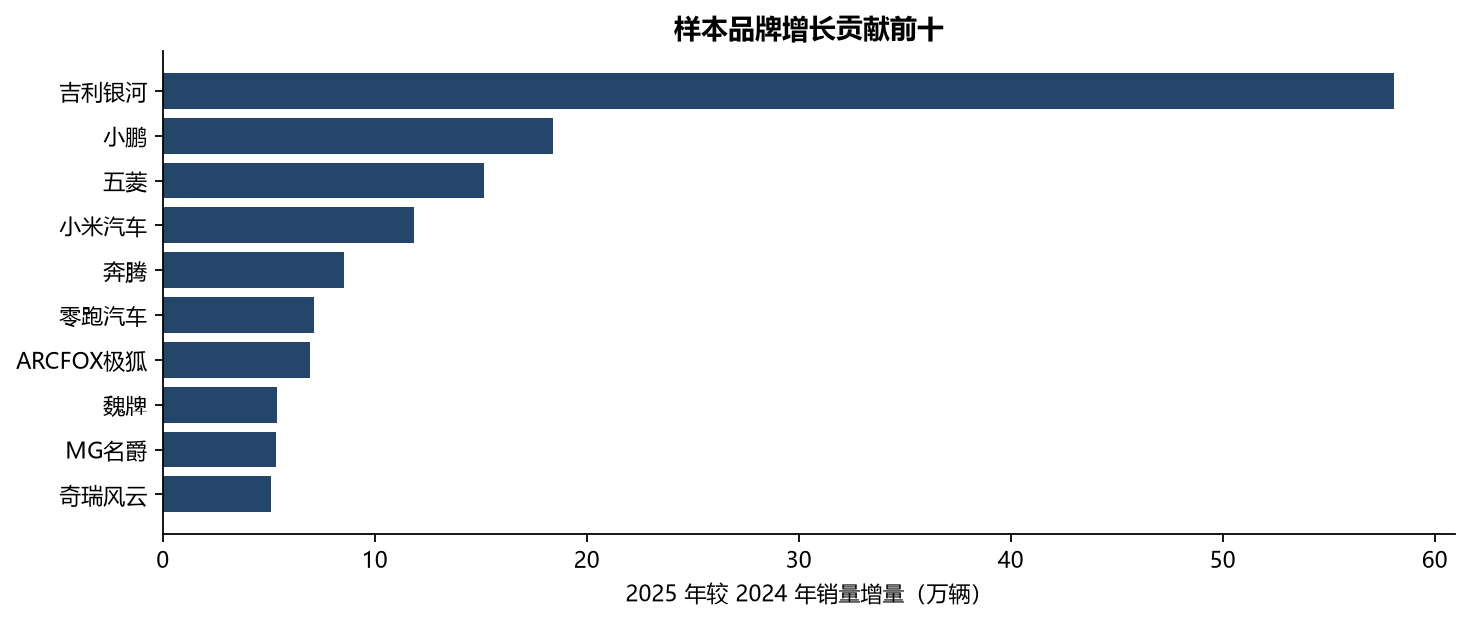

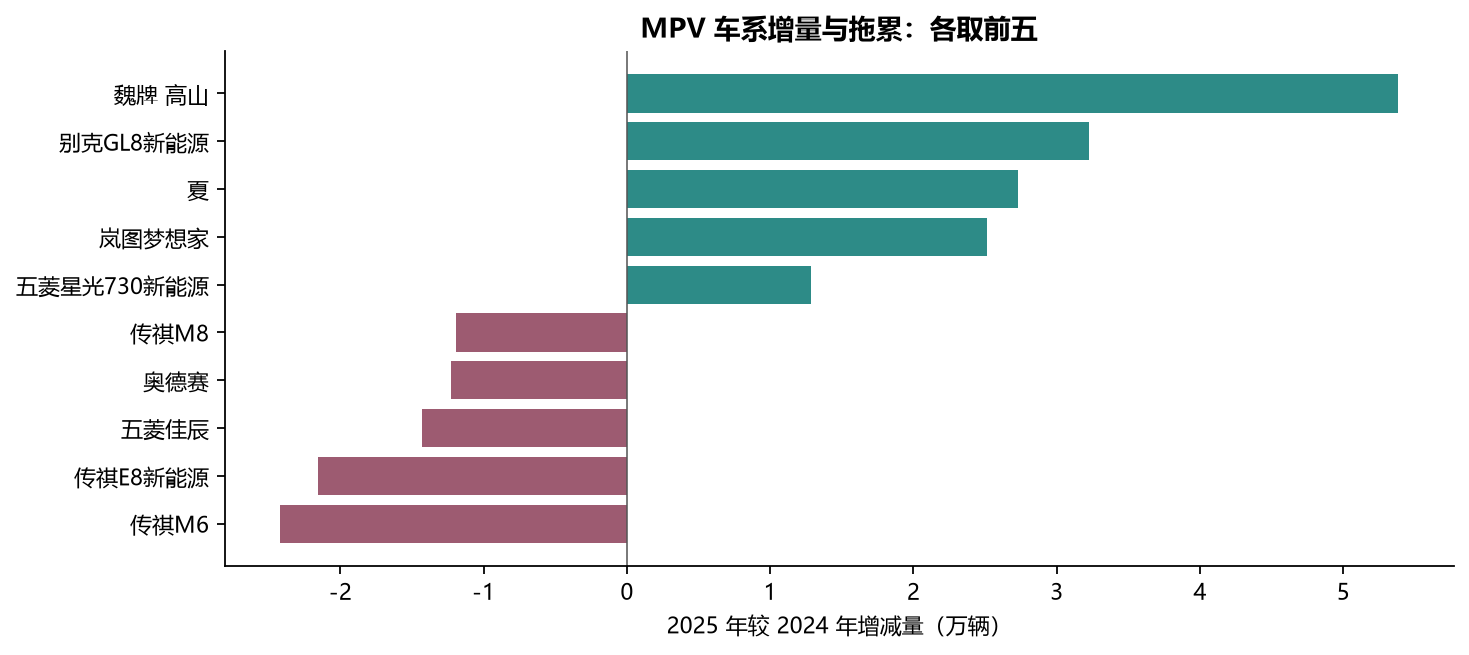

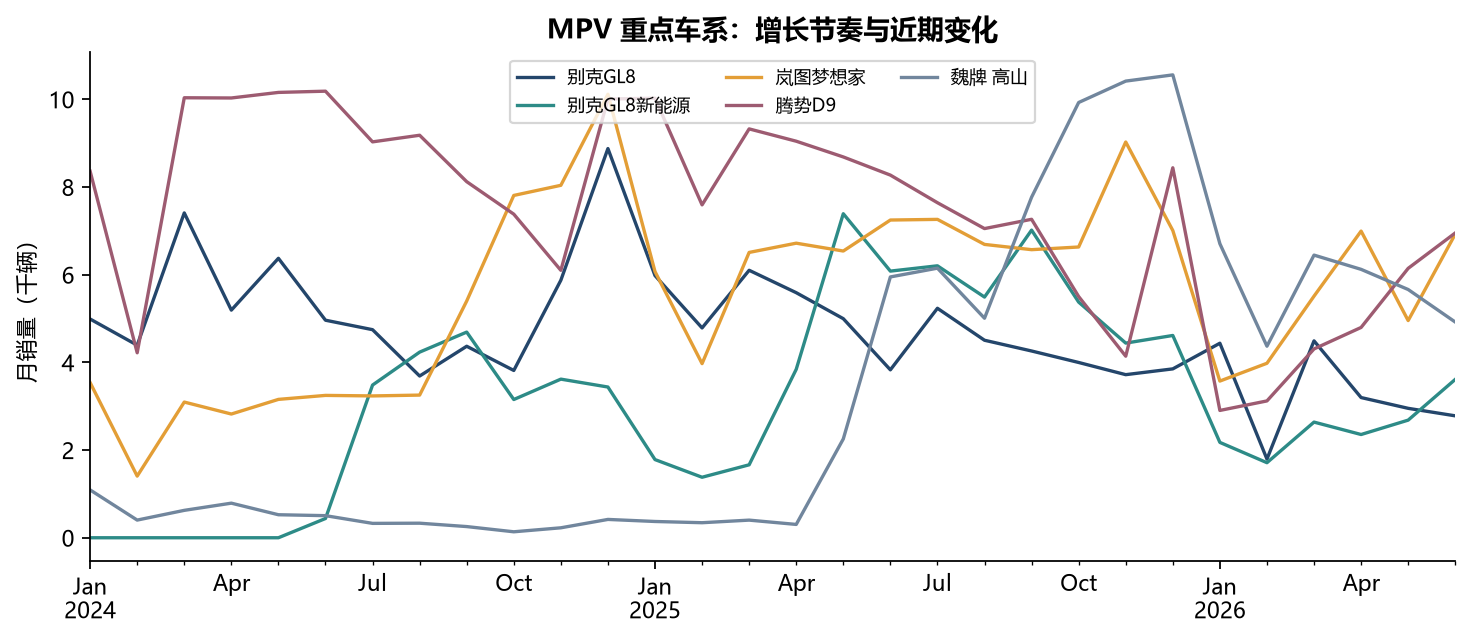

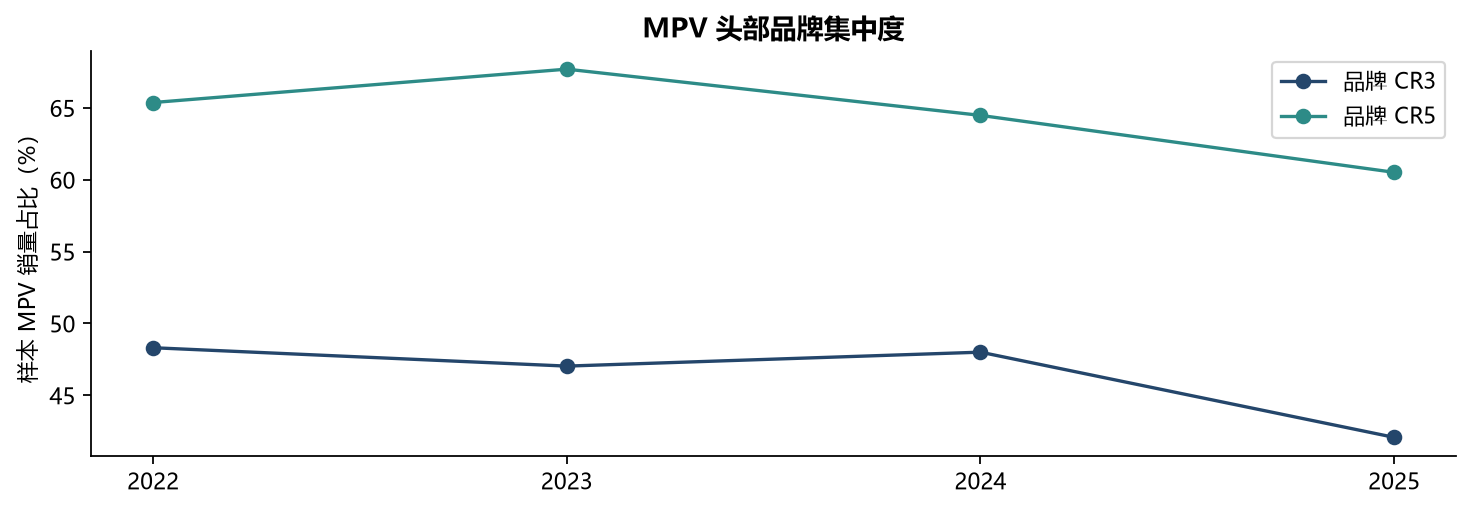

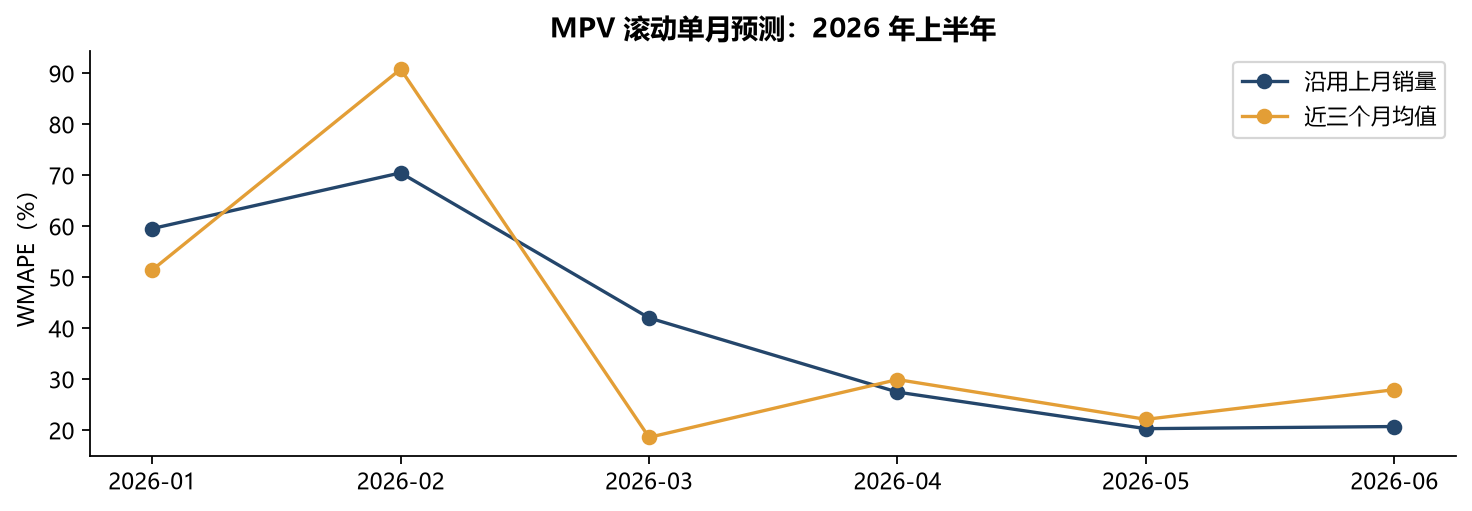

In [11]:
project.charts(sales, outputs)
for name in ['02_brand_growth','03_mpv_growth','04_mpv_trend','05_concentration','06_forecast']:
    display(Image(filename=str(ROOT/'figures'/f'{name}.png'), width=900))

### 核心解释

1. MPV样本2025年仅增长0.69%，车系之间明显分化。高山增量领先，但89.4%的全年增量来自下半年，存在爬坡影响。
2. 别克MPV增长主要来自GL8新能源；其增量大于品牌净增量，部分增长被燃油GL8下降抵消。不能据此证明消费者发生了具体的内部转购。
3. 梦想家2025年增长45.6%，但四季度增量转负，2026上半年同比下降13.8%；历史增长未持续到最近观察期。
4. 品牌CR5由64.48%降至60.52%，下降3.96个百分点。该集中度只适用于样本MPV。
5. 三月均值WMAPE为37.70%，上月基准39.36%；前者仅在6个月中的2个月胜出，总体较优不代表逐月稳定更优。

建议优先跟踪上述车系后续的销量、滚动三月同比及份额。价格、渠道、补贴、交付节奏等原因未被本数据识别，不作因果结论。

### 后续学习顺序

先读load_and_audit；再手写一个品牌月销量GROUP BY；随后重做别克贡献分解；最后解释预测指标。不要仅背诵结论。